# Análisis exploratorio, ANOVA y regresión

Este notebook analiza 118 sesiones de lectura para responder una pregunta concreta: qué factores
influyen en la concentración, en la cantidad de páginas leídas y en la duración de la sesión.

El recorrido va de lo descriptivo a lo inferencial: primero se describe y limpia el conjunto, después
se contrastan hipótesis con ANOVA y por último se ajusta un modelo de mínimos cuadrados para cada
variable de interés. Cada paso incluye la decisión tomada y el porqué.


# DataSet

Se selecciona el dataset https://www.kaggle.com/datasets/chibangng/reading-performance/data, el cual proporciona un conjunto de datos sobre el rendimiento de lectura con factores demográficos y contextuales.

## Objetivo

Comprender cómo diferentes elementos afectan el rendimiento y la concentración en las sesiones de lectura.

## Acciones

Se plantea realizar una serie de análisis con el fin de entender el dataset, por ejemplo un analisis estadístico, analisis de varianza y las transformaciones necesarias que nos ayuden a llegar a conclusiones que permitan dar respuesta al objetivo planteado.

## Estructura del conjunto de datos

Los datos y nombres de columnas estan en el idioma Inglés, a continuación se describen las columnas del dataset:

- **AGE_CATEGORY**: Grupo de edad del lector (por ejemplo, young_adult).
- **GENDER**: Género de la persona que lee (por ejemplo, male, female).
- **MAJOR**: Especialización académica o rol del lector (por ejemplo, student).
- **MINUTES_READING**: Duración total (en minutos) dedicada a la lectura activa durante la sesión.
- **MINUTES_BREAK**: Tiempo total de descanso (en minutos) tomado durante la lectura.
- **FOCUS_LEVEL**: Nivel de concentración durante la lectura. Los valores más altos indican mayor concentración.
- **PAGES**: Número de páginas leídas durante la sesión.
- **CONTENT_LEVEL_ENUM**: Nivel de dificultad del material de lectura.
- **READING_GENRE**: Género del material de lectura (por ejemplo, academic, language, self-development).
- **SOUND_VOLUME**: Intensidad del sonido ambiental durante la lectura, que varía desde silencioso a extremadamente fuerte.
- **DEVICE**: Dispositivo o medio utilizado para leer (por ejemplo, laptop, smartphone, book, tablet).
- **LOCATION**: Entorno físico donde tuvo lugar la sesión de lectura (por ejemplo, home, library, café).
- **WEATHER**: Condiciones climáticas durante la sesión de lectura (por ejemplo, sunny, rainy, cloudy).
- **MOOD**: Estado emocional del lector durante la sesión, de muy malo a muy bueno.
- **HUNGER**: Nivel de hambre o saciedad durante la lectura.
- **AROUSAL**: Nivel de excitación cognitiva, de muy bajo a muy alto.
- **MENTAL_IN_BREAK**: Estado mental durante los descansos (por ejemplo, chaotic, neutral, calm).
- **COMPREHENSION_DEPTH**: Profundidad de comprensión alcanzada durante la lectura (por ejemplo, basic, good).
- **LINKING_TO_PREVIOUS_KNOWLEDGE**: Grado en que el contenido se relaciona con el conocimiento previo (por ejemplo, forced_linking, some_connections).
- **MENTAL_FATIGUE**: Nivel de fatiga mental durante la sesión (por ejemplo, fresh, slightly_fatigued).
- **INTERESTING_LEVEL**: Grado de interés en el material de lectura (por ejemplo, neutral, somewhat_interesting).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

df = pd.read_parquet("data/reading.parquet", engine="pyarrow")

# Análisis Estadístico Descriptivo y Exploratorio

### Medidas de tendencia Central
Se procederá a calcular las medidas de tendencia central como son: la media, mediana y moda, con el fin de encontrar un valor representativo.

Adicionalmente se calculará el mínimo, el máximo y cuartiles.
    
### Técnicas de detección de outliers

Se usará **El Método de los Cuartiles** (Rango Intercuartílico - IQR), que es una forma sencilla para hacerlo. Este método consiste en calcular la distancia entre el percentil 25(q1) y 75(q3), y cualquier dato que esté 1.5 veces fuera del rango se considera outliers. Adicionalemte se usará la grafica Boxplot (diagrama de caja) para hacerlo de forma visual, en este diagrama si hay puntos fuera de los "bigotes" de la caja, son los registros outliers.

### Visualización

Se usarán los histogramas para valores númericos y los diagramas de barras para categorías.


------------------------- MINUTES_READING  -------------------------
Media: 77.78
Mediana: 70.5
Moda: 60
Mínimo: 12
Máximo: 456

 Qs      %
0.25    48.5
0.50    70.5
0.75    95.0
Name: MINUTES_READING, dtype: float64

Outliers:
Límite inferior: -21.25, límite superior: 164.75, cant. registros 2 


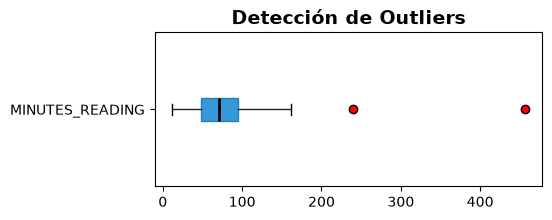

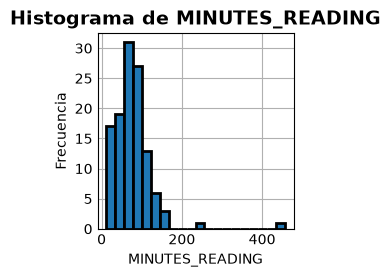


------------------------- MINUTES_BREAK  -------------------------
Media: 10.47
Mediana: 4.5
Moda: 0
Mínimo: 0
Máximo: 165

 Qs      %
0.25     0.0
0.50     4.5
0.75    15.0
Name: MINUTES_BREAK, dtype: float64

Outliers:
Límite inferior: -22.5, límite superior: 37.5, cant. registros 7 


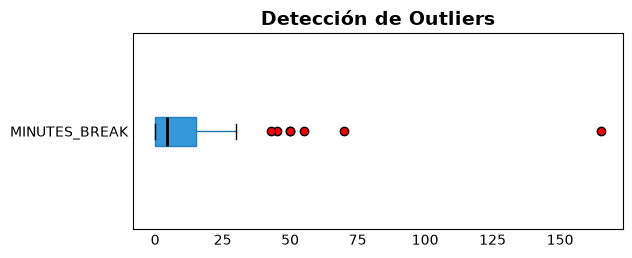

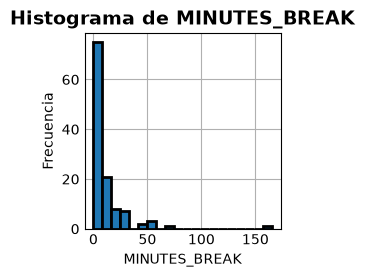


------------------------- FOCUS_LEVEL  -------------------------
Media: 2.64
Mediana: 3.0
Moda: 3
Mínimo: 1
Máximo: 3

 Qs      %
0.25    2.0
0.50    3.0
0.75    3.0
Name: FOCUS_LEVEL, dtype: float64

Outliers:
Límite inferior: 0.5, límite superior: 4.5, cant. registros 0 


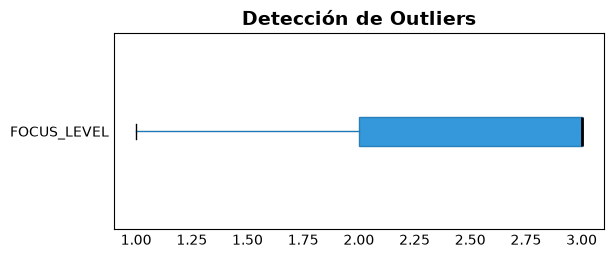

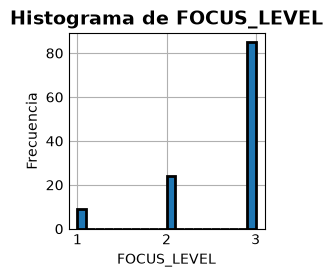


------------------------- PAGES  -------------------------
Media: 10.74
Mediana: 8.0
Moda: 8.0
Mínimo: 1.0
Máximo: 51.0

 Qs      %
0.25     4.0
0.50     8.0
0.75    14.0
Name: PAGES, dtype: float64

Outliers:
Límite inferior: -11.0, límite superior: 29.0, cant. registros 6 


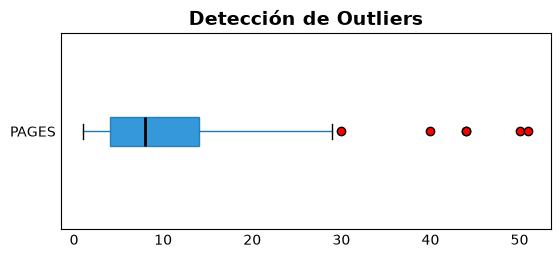

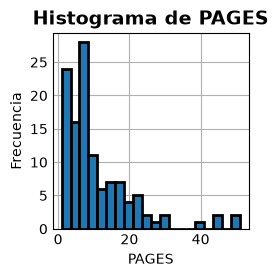


------------------------- CONTENT_LEVEL_ENUM  -------------------------
Media: 2.27
Mediana: 3.0
Moda: 3
Mínimo: 1
Máximo: 3

 Qs      %
0.25    2.0
0.50    3.0
0.75    3.0
Name: CONTENT_LEVEL_ENUM, dtype: float64

Outliers:
Límite inferior: 0.5, límite superior: 4.5, cant. registros 0 


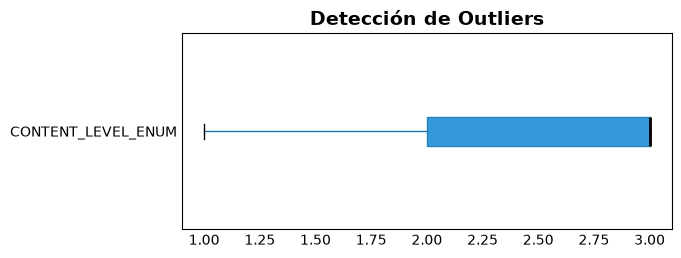

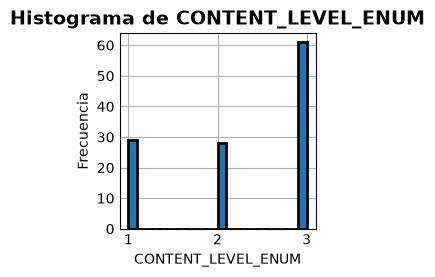


------------------------- AGE_CATEGORY -------------------------
Moda: young_adult - 100.0 %
Categorías: <ArrowStringArray>
['young_adult']
Length: 1, dtype: str


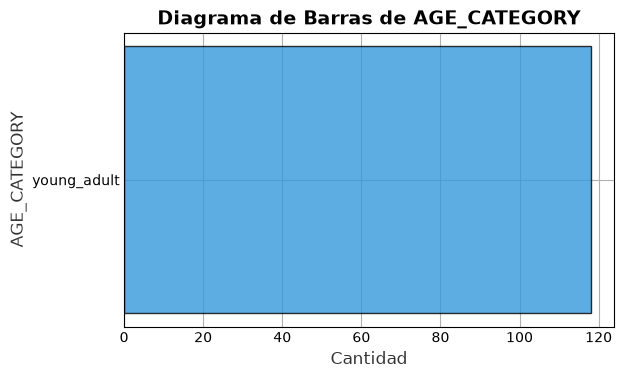


------------------------- GENDER -------------------------
Moda: male - 100.0 %
Categorías: <ArrowStringArray>
['male']
Length: 1, dtype: str


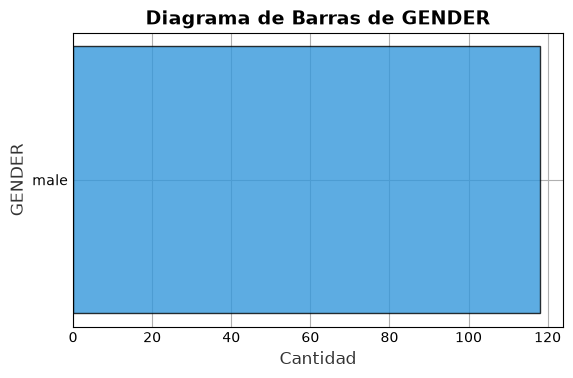


------------------------- MAJOR -------------------------
Moda: student - 100.0 %
Categorías: <ArrowStringArray>
['student']
Length: 1, dtype: str


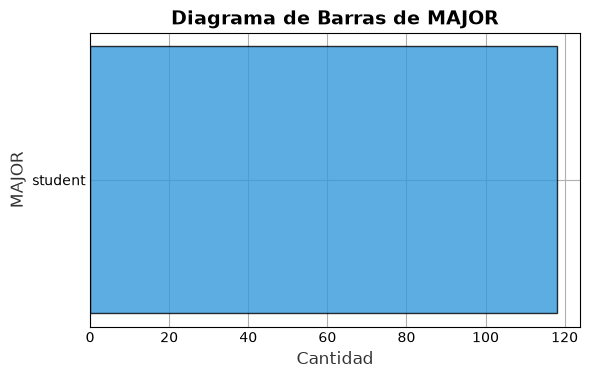


------------------------- READING_GENRE -------------------------
Moda: academic - 69.49 %
Categorías: <ArrowStringArray>
['technical_&_vocational', 'academic', 'self-development', 'language']
Length: 4, dtype: str


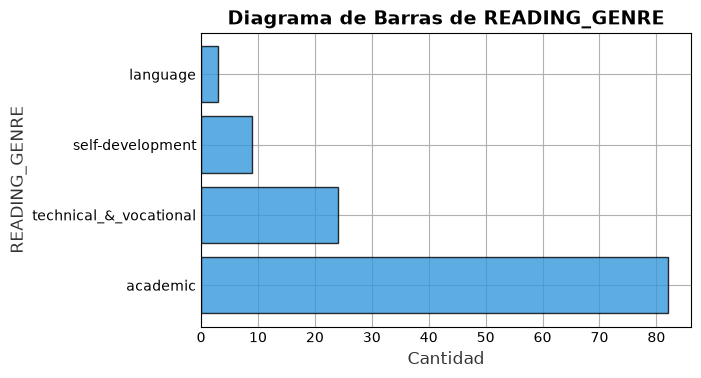


------------------------- MOOD -------------------------
Moda: good - 37.29 %
Categorías: <ArrowStringArray>
['slightly_bad', 'neutral', 'good', 'very_good', 'slightly_good', 'bad']
Length: 6, dtype: str


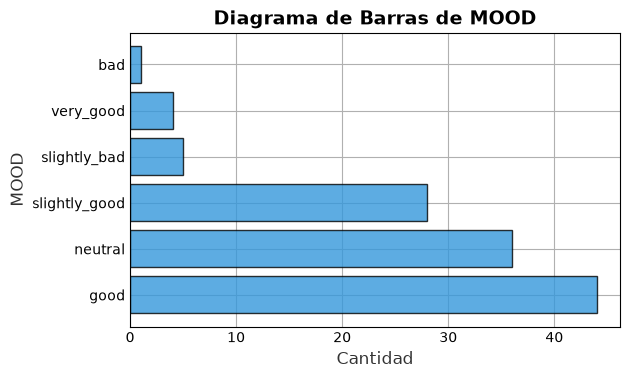


------------------------- HUNGER -------------------------
Moda: satisfied - 27.97 %
Categorías: <ArrowStringArray>
['slightly_hungry',            'full',       'satisfied',     'very_hungry',
       'very_full',   'slightly_full',        'starving',     'overstuffed',
          'hungry',  'extreme_hungry']
Length: 10, dtype: str


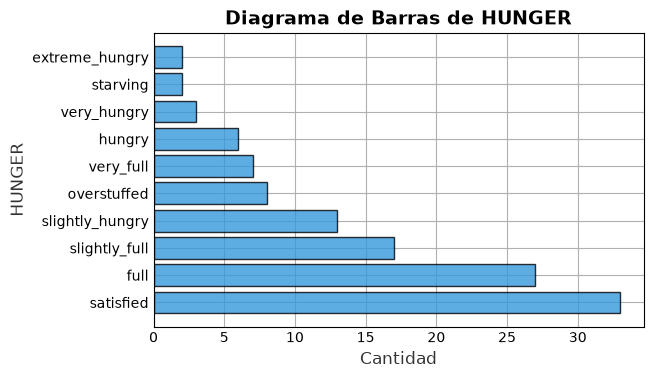


------------------------- AROUSAL -------------------------
Moda: high - 50.85 %
Categorías: <ArrowStringArray>
['slightly_low', 'neutral', 'high', 'slightly_high', 'very_high', 'low']
Length: 6, dtype: str


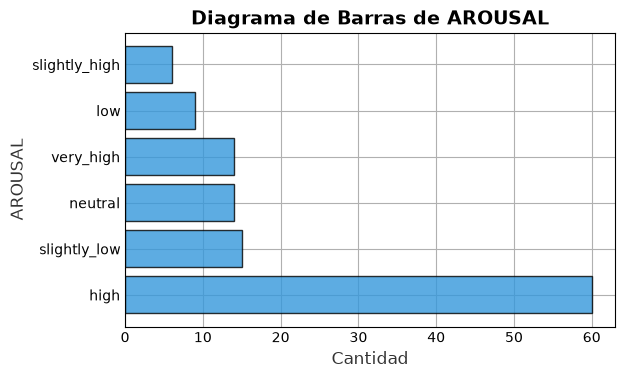


------------------------- SOUND_VOLUME -------------------------
Moda: silent - 49.15 %
Categorías: <ArrowStringArray>
[         'silent',      'very_quiet',           'quiet',        'moderate',
            'loud',  'slightly_quiet', 'almost_moderate',       'very_loud']
Length: 8, dtype: str


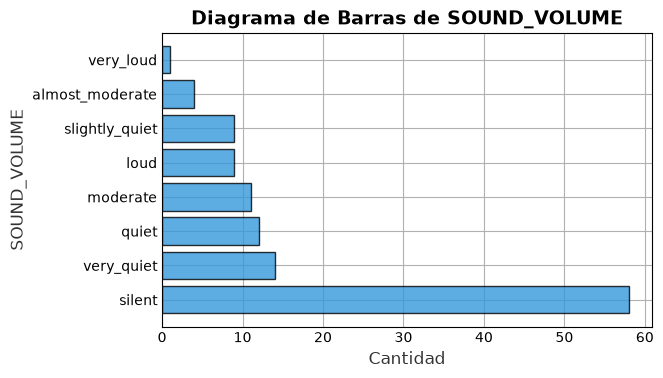


------------------------- DEVICE -------------------------
Moda: laptop - 71.19 %
Categorías: <ArrowStringArray>
['laptop', 'book', 'smartphone']
Length: 3, dtype: str


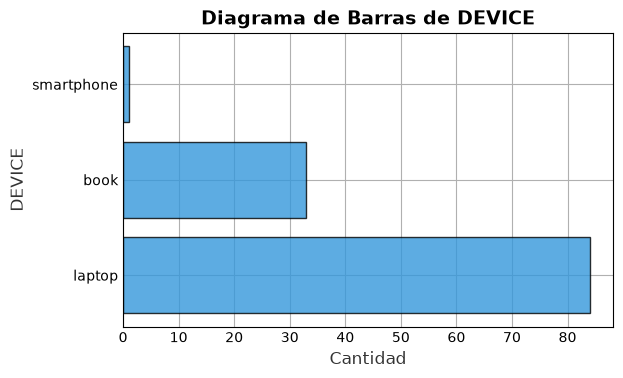


------------------------- LOCATION -------------------------


Moda: home - 85.59 %
Categorías: <ArrowStringArray>
['home', 'library', 'outdoor', 'office']
Length: 4, dtype: str


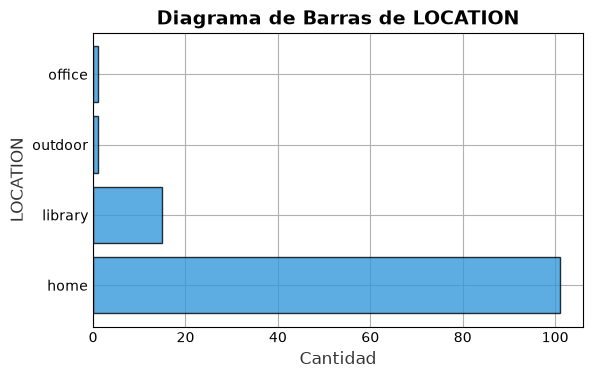


------------------------- WEATHER -------------------------
Moda: clear - 36.44 %
Categorías: <ArrowStringArray>
['clear', 'cloudy', 'rainy', 'sunny', 'stormy']
Length: 5, dtype: str


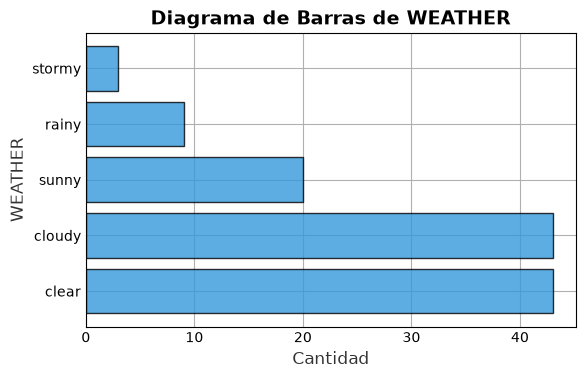


------------------------- MENTAL_IN_BREAK -------------------------
Moda: none_break - 35.59 %
Categorías: <ArrowStringArray>
[         'neutral',          'chaotic',     'very_chaotic',
 'slightly_chaotic',    'slightly_calm',             'calm',
       'none_break',        'very_calm']
Length: 8, dtype: str


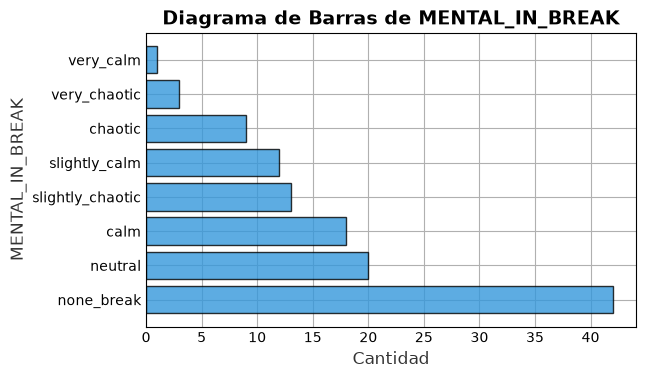


------------------------- COMPREHENSION_DEPTH -------------------------
Moda: good - 30.51 %
Categorías: <ArrowStringArray>
['good', 'basic', 'mastery', 'strong', 'minimal', 'moderate',
 'no_understanding']
Length: 7, dtype: str


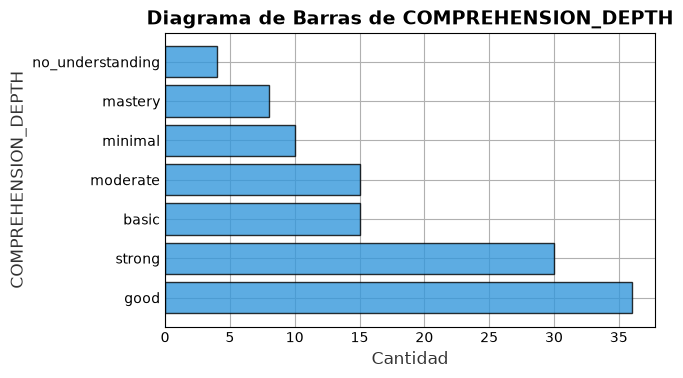


------------------------- LINKING_TO_PREVIOUS_KNOWLEDGE -------------------------
Moda: some_connections - 47.46 %
Categorías: <ArrowStringArray>
[         'some_connections',            'forced_linking',
           'natural_linking',        'no_connection_made',
 'integrated_into_framework']
Length: 5, dtype: str


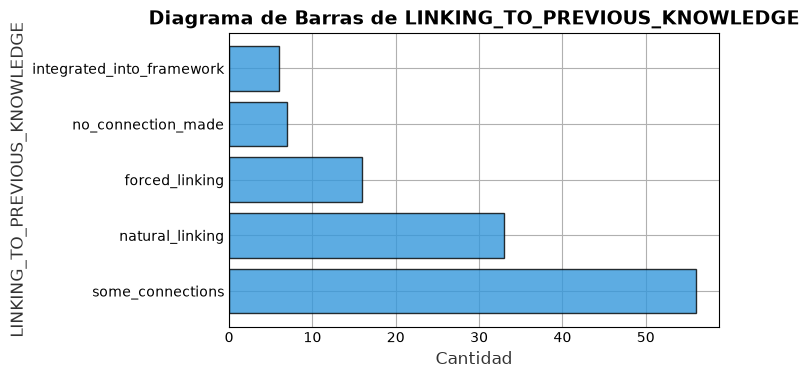


------------------------- MENTAL_FATIGUE -------------------------


Moda: normal - 33.05 %
Categorías: <ArrowStringArray>
['slightly_fatigued',             'fresh',            'normal',
   'extremely_fresh',     'very_fatigued',        'very_fresh',
          'fatigued']
Length: 7, dtype: str


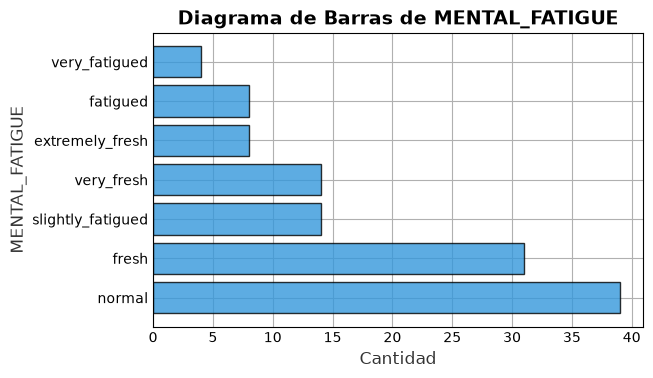


------------------------- INTERESTING_LEVEL -------------------------
Moda: interesting - 27.12 %
Categorías: <ArrowStringArray>
[              'neutral',  'somewhat_interesting',                'boring',
      'extremely_boring', 'extremely_interesting',           'interesting',
           'very_boring']
Length: 7, dtype: str


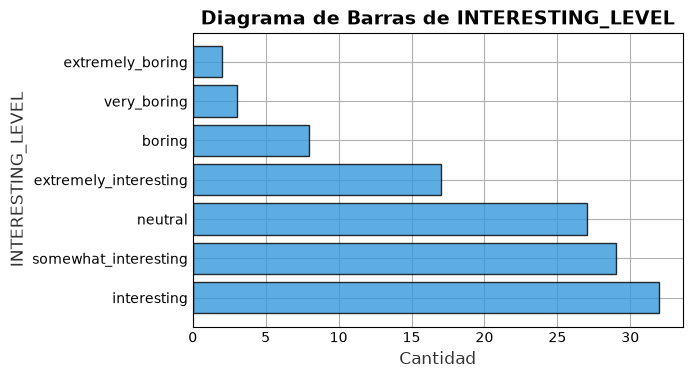

---------------------------------- Resumen ----------------------------------


,AGE_CATEGORY,GENDER,MAJOR,MINUTES_READING,MINUTES_BREAK,FOCUS_LEVEL,PAGES,CONTENT_LEVEL_ENUM,READING_GENRE,SOUND_VOLUME,...,LOCATION,WEATHER,MOOD,HUNGER,AROUSAL,MENTAL_IN_BREAK,COMPREHENSION_DEPTH,LINKING_TO_PREVIOUS_KNOWLEDGE,MENTAL_FATIGUE,INTERESTING_LEVEL
count,118,118,118,118.000000,118.000000,118.000000,118.000000,118.000000,118,118,...,118,118,118,118,118,118,118,118,118,118
unique,1,1,1,NaN,NaN,NaN,NaN,NaN,4,8,...,4,5,6,10,6,8,7,5,7,7
top,young_adult,male,student,NaN,NaN,NaN,NaN,NaN,academic,silent,...,home,clear,good,satisfied,high,none_break,good,some_connections,normal,interesting
freq,118,118,118,NaN,NaN,NaN,NaN,NaN,82,58,...,101,43,44,33,60,42,36,56,39,32
mean,NaN,NaN,NaN,77.779661,10.466102,2.644068,10.741525,2.271186,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,50.450303,19.374264,0.620524,10.065328,0.833703,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,12.000000,0.000000,1.000000,1.000000,1.000000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,48.500000,0.000000,2.000000,4.000000,2.000000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,70.500000,4.500000,3.000000,8.000000,3.000000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,95.000000,15.000000,3.000000,14.000000,3.000000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
def crear_histograma(data, titulo, xlabel, ylabel, rotacion):
    plt.style.use("_mpl-gallery")
    fig, ax = plt.subplots()
    ax.hist(data, linewidth=2, edgecolor="black", bins=20)
    ax.set_title(titulo, fontsize=14, fontweight='bold')
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.xticks(rotation=rotacion)
    plt.show()

def crear_diagrama_barras(data, titulo, xlabel, ylabel):
    conteo_categorias = data.value_counts()
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.barh(conteo_categorias.index, conteo_categorias.values, color='#3498db', 
            edgecolor='black', alpha=0.8)
    ax.set_title(titulo, fontsize=14, fontweight='bold')
    ax.set_xlabel(ylabel, fontsize=12, fontweight='regular', color='#333333')
    ax.set_ylabel(xlabel, fontsize=12, fontweight='regular', color='#333333')
    plt.show()


def crear_boxplot(columna):
    plt.figure(figsize=(5, 2))
    box = df.boxplot(column=columna, vert=False, 
                     patch_artist=True, # Permite rellenar con color
                     medianprops={'color': 'black', 'linewidth': 2},
                     boxprops={'facecolor': '#3498db', 'edgecolor': '#2980b9'},
                     flierprops={'markerfacecolor': 'red', 'marker': 'o'}
    )

    plt.title("Detección de Outliers", fontsize=14, fontweight='bold')
    plt.grid(False)
    plt.show()

def detectar_outliers_metodo_cuartiles(columna):
    data = df[columna]
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    
    # Se calcula el Rango Intercuartílico (IQR)
    iqr = q3 - q1
    
    # Se definen los límites (Bigotes)
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    
    # Se filtrar los valores fuera de los límites
    outliers = df[(df[columna] < limite_inferior) | (df[columna] > limite_superior)]

    return (limite_inferior, limite_superior, outliers)


def analisis_datos_numericos(columna, titulo, xlabel, ylabel):
    data = df[columna]
    
    print(f"\n------------------------- {columna}  -------------------------")
    media = data.mean()
    print(f"Media: {round(media, 2)}")
    mediana = data.median()
    print(f"Mediana: {mediana}")
    moda = data.mode()[0]
    print(f"Moda: {moda}")

    minimo = data.min()
    print(f"Mínimo: {minimo}")
    maximo = data.max()
    print(f"Máximo: {maximo}")
    cuartiles = data.quantile([0.25, 0.5, 0.75])
    print("\n Qs      %")
    print(cuartiles)
    print("\nOutliers:")
    limite_inferior, limite_superior, outliers = detectar_outliers_metodo_cuartiles(columna)
    num_registros = outliers[columna].count()
    print(f"Límite inferior: {limite_inferior}, límite superior: {limite_superior}, cant. registros {num_registros} ")
    crear_boxplot(columna)
    crear_histograma(data, titulo, xlabel, ylabel, 0)

def analisis_datos_string(columna, titulo, xlabel, ylabel):
    data = df[columna]
    registros = data.count()
    
    print(f"\n------------------------- {columna} -------------------------")
    moda = data.mode()[0]
    porcentaje = round((data[df[columna] == moda].count() * 100) / registros, 2)
    print(f"Moda: {moda} - {porcentaje} %")
    categorias = data.unique()
    print(f"Categorías: {categorias}")
    crear_diagrama_barras(data, titulo, xlabel, ylabel)				

columnas_numericas_analizar = [ "MINUTES_READING", "MINUTES_BREAK", "FOCUS_LEVEL",
                              "PAGES", "CONTENT_LEVEL_ENUM"]

for columna in columnas_numericas_analizar:
    analisis_datos_numericos(columna,
                             f"Histograma de {columna}",
                             columna, "Frecuencia")

columnas_str_analizar = ["AGE_CATEGORY", "GENDER", "MAJOR", "READING_GENRE",
                         "MOOD", "HUNGER", "AROUSAL", 
                         "SOUND_VOLUME", "DEVICE", "LOCATION", "WEATHER",
                         "MENTAL_IN_BREAK",
                         "COMPREHENSION_DEPTH", "LINKING_TO_PREVIOUS_KNOWLEDGE", "MENTAL_FATIGUE", "INTERESTING_LEVEL"]

for columna in columnas_str_analizar:
    analisis_datos_string(columna, 
                          f"Diagrama de Barras de {columna}",
                         columna, "Cantidad")

# Resumen
print(f"---------------------------------- Resumen ----------------------------------")
df.describe(include="all")


Al realizar el análisis estadístico descriptivo y exploratorio se encuentra que hay valores outliers por lo cual en la siguiente sección se abordarán. También se encuentran 3 columnas o variables (MAJOR, GENDER y AGE_CATEGORY) con un único valor lo que indica que no aportan información predictiva. En total hay 5 valores númericos en el cual uno de ellos (CONTENT_LEVEL_ENUM) actúa como categoría al igual que las 15 columnas restantes.

# Tratamiento de datos, transformaciones

### Valores Nan

Vale la pena aclarar que este dataset no contiene valores Nan, pero en el caso que fuera necesario tratar con valores Nan, la información anterior era relenvante, ya que, a continuación se describen algunas técnicas en la que esta información hubiera sido necesaria:

- **Eliminación**: Se recomienda cuando los datos faltantes superan el 60%, aunque se corre el riesgo de perder información cuando los datos que faltan siguen un patrón.  
- **Sustitución Simple**: Si los datos que faltan son menos del 10% se puede sustituir con la Media (si los datos son simétricos) o la Mediana (si hay valores extremos) y para variables que representen categórias se puede usar la Moda.
- **Sustitución Avanzada**: Usar algoritmos como KNN o Iterative Imputer con el fin de predecir los valores faltantes a partir de otras columnas.

### Valores outliers

Se detecto que las columnas MINUTES_READING (2), MINUTES_BREAK(7) y PAGES(6) tienen valores atipicos, a pesar de esto, es facil darse cuenta que son valores que describen eventos reales aunque extremos en comparación con los demás datos. Por lo anterior no se eliminan, ya que no son errores. El tratamiento que se realizará a cada columna es la siguiente:

**MINUTES_READING**, al tener solo 2 registros que representan un 1,67 % este porcentaje representa un riesgo bajo de sesgar las conclusiones, por lo cual se aplicará la **Winsorización** que consiste en que en lugar de eliminar un outlier, se le asigna un valor máximo o mínimo permitido, en este caso se le asignará el valor máximo permitido (164.75).

**MINUTES_BREAK** y **PAGES**, al tene 7 y 6 registros respectivamente que representan un 5.93% y 5.03% estos porcentajes representan un riesgo considerable de sesgar las conclusiones por lo cual se hará una **transformación logaritmica** (comprime los valores grandes y expande los pequeños). Es importante aclarar que para las pruebas estadísticas, lo que importa es la relación entre los números, no su valor absoluto. Aunque si es necesario en algun momento el valor real se puede "revertir" el logaritmo usando np.expm1().

Luego del tratamiento se vuelven a mostrar los diagramas de caja para revisar cisualmente que ya no hayan valores outliers.

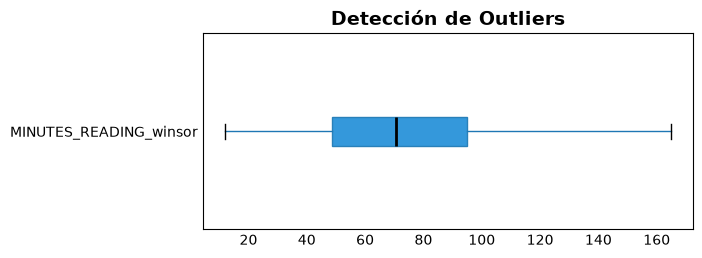

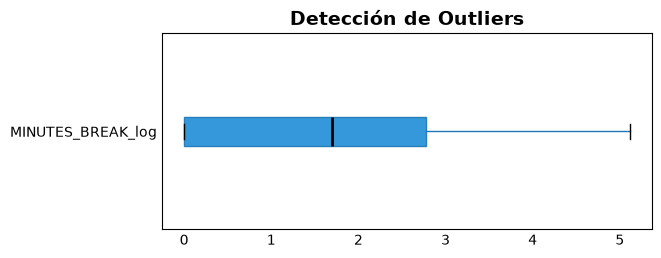

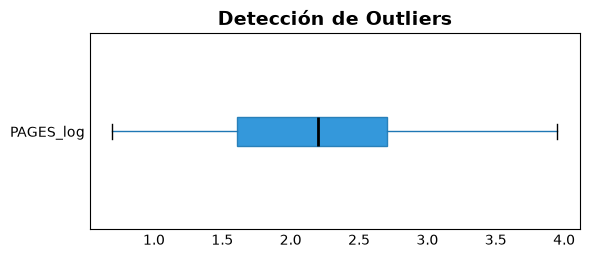

,AGE_CATEGORY,GENDER,MAJOR,MINUTES_READING,MINUTES_BREAK,FOCUS_LEVEL,PAGES,CONTENT_LEVEL_ENUM,READING_GENRE,SOUND_VOLUME,...,HUNGER,AROUSAL,MENTAL_IN_BREAK,COMPREHENSION_DEPTH,LINKING_TO_PREVIOUS_KNOWLEDGE,MENTAL_FATIGUE,INTERESTING_LEVEL,MINUTES_READING_winsor,MINUTES_BREAK_log,PAGES_log
count,118,118,118,118.000000,118.000000,118.000000,118.000000,118.000000,118,118,...,118,118,118,118,118,118,118,118.000000,118.000000,118.000000
unique,1,1,1,NaN,NaN,NaN,NaN,NaN,4,8,...,10,6,8,7,5,7,7,NaN,NaN,NaN
top,young_adult,male,student,NaN,NaN,NaN,NaN,NaN,academic,silent,...,satisfied,high,none_break,good,some_connections,normal,interesting,NaN,NaN,NaN
freq,118,118,118,NaN,NaN,NaN,NaN,NaN,82,58,...,33,60,42,36,56,39,32,NaN,NaN,NaN
mean,NaN,NaN,NaN,77.779661,10.466102,2.644068,10.741525,2.271186,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,74.673729,1.539362,2.162240
std,NaN,NaN,NaN,50.450303,19.374264,0.620524,10.065328,0.833703,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,34.888781,1.379240,0.781499
min,NaN,NaN,NaN,12.000000,0.000000,1.000000,1.000000,1.000000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.000000,0.000000,0.693147
25%,NaN,NaN,NaN,48.500000,0.000000,2.000000,4.000000,2.000000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,48.500000,0.000000,1.609438
50%,NaN,NaN,NaN,70.500000,4.500000,3.000000,8.000000,3.000000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.500000,1.700599,2.197225
75%,NaN,NaN,NaN,95.000000,15.000000,3.000000,14.000000,3.000000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,95.000000,2.772589,2.708050


In [3]:
# winsorización
df["MINUTES_READING_winsor"] = df["MINUTES_READING"].clip(upper=164.75)

# transformación logarítmica
df["MINUTES_BREAK_log"] = np.log1p(df["MINUTES_BREAK"])
df["PAGES_log"] = np.log1p(df["PAGES"])

crear_boxplot("MINUTES_READING_winsor")
crear_boxplot("MINUTES_BREAK_log")
crear_boxplot("PAGES_log")

df.describe(include="all")

# Análisis de varianza

Una vez realizado el análisis estadístico descriptivo y exploratorio, y una vez realizado el tratamiendo de datos y su transformación, se procederá a calcular medidas de dispersión: Desviación Estándar y Varianza, con el fin de determinar la consistencia de los datos.

In [4]:
columnas_numericas_analizar = [ "MINUTES_READING_winsor", "MINUTES_BREAK_log", "FOCUS_LEVEL",
                              "PAGES_log", "CONTENT_LEVEL_ENUM"]

for columna in columnas_numericas_analizar:  
    varianza = round(df[columna].var(), 2)
    desviacion = round(df[columna].std(), 2)
    titulo = columna + " " * (23 - len(columna))
    print(f"\t{titulo}: \tVarianza {varianza}    \tDesviación Estandar {desviacion}")

	MINUTES_READING_winsor : 	Varianza 1217.23    	Desviación Estandar 34.89
	MINUTES_BREAK_log      : 	Varianza 1.9    	Desviación Estandar 1.38
	FOCUS_LEVEL            : 	Varianza 0.39    	Desviación Estandar 0.62
	PAGES_log              : 	Varianza 0.61    	Desviación Estandar 0.78
	CONTENT_LEVEL_ENUM     : 	Varianza 0.7    	Desviación Estandar 0.83


Al observar la varianza y la desviación estandar se puede decir que:
- **MINUTES_READING_winsor**: La desviación de casi 35 minutos indica que las sesiones de lectura varían drásticamente entre sí. A pesar de la Winsorización, el ruido es alto por lo que es evidente que esta es la variable más volátil del dataset.
- **MINUTES_BREAK_log**: Tiene una desviación considerable, ya que, en las escalas logarítmicas los valores suelen ser pequeños; esto indica que posiblemente en la escala original (minutos reales) tiene una dispersión muy amplia.
- **FOCUS_LEVEL**: Una varianza de 0.39 indica que la mayoría de los valores están muy cerca del promedio, es decir, hay mucha homogeneidad.
- **PAGES_log**: La varianza de 0.61 es baja, lo que indica que el volumen de páginas leídas, una vez transformada, es bastante consistente. 
- **CONTENT_LEVEL_ENUM**: Al tener una desviación menor a 1 sugiere que los datos no saltan bruscamente entre niveles extremos, sino que se concentran en niveles adyacentes.

Como conlusión general en este análisis se puede decir que la varianza baja en FOCUS_LEVEL y CONTENT_LEVEL_ENUM es ideal para el paso siguiente (ANOVA), mientras que las variables a las que se les aplicó la transformación logarítmica (MINUTES_BREAK_log, PAGES_log) han logrado reducir lo que probablemente eran varianzas grandes a números manejables (1.9 y 0.61).

# Anova

Se investiga sobre Anova la cual es una Pruebas de Significancia y se encuentra que antes de ANOVA se recomienda realizar el Test de Levene, este test verifica la Homocedasticidad (que las varianzas sean iguales entre grupos).

Para el Test de Levene y ANOVA se excluyen las columnas donde solo hay un valor por lo cual no influyen, dado que no aportan información predictiva, estas son:

- MAJOR (student)
- GENDER (male)
- AGE_CATEGORY (young_adult).

Se proceden a agrupar las categorias con un efecto. Se tomarán como efectos las siguiente columnas o variables:

- MINUTES_READING_winsor
- FOCUS_LEVEL
- PAGES_log

El resto de columnas o variables se usarán como categorías.

In [5]:
def realizar_levene(efecto, categoria):
    grupos = [group[efecto].values for name, group in df.groupby(categoria)]
    stat_levene, p_levene = stats.levene(*grupos)
    print(f"--- Levene para: {efecto} según {categoria} ---")
    print(f"Estadístico: {stat_levene:.4f}")
    print(f"Valor p: {p_levene:.4f}")
    if p_levene > 0.05:
        print("Varianzas homogéneas.\n")
    else:
        print("Varianzas desiguales.\n")

"""
    Se realiza el test de levene para las combinaciones efecto según categoría
    por ejemplo, si el SOUND_VOLUME (Intensidad del sonido ambiental durante la lectura) 
    afecta el MINUTES_READING (tiempo dedicado a la lectura), en este ejemplo SOUND_VOLUME
    es la categoría y MINUTES_READING el efecto.
"""
realizar_levene(efecto="MINUTES_READING_winsor", categoria="SOUND_VOLUME")
realizar_levene(efecto="FOCUS_LEVEL", categoria="SOUND_VOLUME")
realizar_levene(efecto="PAGES_log", categoria="SOUND_VOLUME")

realizar_levene(efecto="MINUTES_READING_winsor", categoria="CONTENT_LEVEL_ENUM")
realizar_levene(efecto="FOCUS_LEVEL", categoria="CONTENT_LEVEL_ENUM")
realizar_levene(efecto="PAGES_log", categoria="CONTENT_LEVEL_ENUM")

realizar_levene(efecto="MINUTES_READING_winsor", categoria="HUNGER")
realizar_levene(efecto="FOCUS_LEVEL", categoria="HUNGER")
realizar_levene(efecto="PAGES_log", categoria="HUNGER")

realizar_levene(efecto="MINUTES_READING_winsor", categoria="COMPREHENSION_DEPTH")
realizar_levene(efecto="FOCUS_LEVEL", categoria="COMPREHENSION_DEPTH")
realizar_levene(efecto="PAGES_log", categoria="COMPREHENSION_DEPTH")

realizar_levene(efecto="MINUTES_READING_winsor", categoria="LINKING_TO_PREVIOUS_KNOWLEDGE")
realizar_levene(efecto="FOCUS_LEVEL", categoria="LINKING_TO_PREVIOUS_KNOWLEDGE")
realizar_levene(efecto="PAGES_log", categoria="LINKING_TO_PREVIOUS_KNOWLEDGE")

realizar_levene(efecto="MINUTES_READING_winsor", categoria="MENTAL_FATIGUE")
realizar_levene(efecto="FOCUS_LEVEL", categoria="MENTAL_FATIGUE")
realizar_levene(efecto="PAGES_log", categoria="MENTAL_FATIGUE")

realizar_levene(efecto="MINUTES_READING_winsor", categoria="INTERESTING_LEVEL")
realizar_levene(efecto="FOCUS_LEVEL", categoria="INTERESTING_LEVEL")
realizar_levene(efecto="PAGES_log", categoria="INTERESTING_LEVEL")

realizar_levene(efecto="MINUTES_READING_winsor", categoria="CONTENT_LEVEL_ENUM")
realizar_levene(efecto="FOCUS_LEVEL", categoria="CONTENT_LEVEL_ENUM")
realizar_levene(efecto="PAGES_log", categoria="CONTENT_LEVEL_ENUM")

realizar_levene(efecto="MINUTES_READING_winsor", categoria="DEVICE")
realizar_levene(efecto="FOCUS_LEVEL", categoria="DEVICE")
realizar_levene(efecto="PAGES_log", categoria="DEVICE")

realizar_levene(efecto="MINUTES_READING_winsor", categoria="LOCATION")
realizar_levene(efecto="FOCUS_LEVEL", categoria="LOCATION")
realizar_levene(efecto="PAGES_log", categoria="LOCATION")

realizar_levene(efecto="MINUTES_READING_winsor", categoria="READING_GENRE")
realizar_levene(efecto="FOCUS_LEVEL", categoria="READING_GENRE")
realizar_levene(efecto="PAGES_log", categoria="READING_GENRE")

realizar_levene(efecto="MINUTES_READING_winsor", categoria="WEATHER")
realizar_levene(efecto="FOCUS_LEVEL", categoria="WEATHER")
realizar_levene(efecto="PAGES_log", categoria="WEATHER")

realizar_levene(efecto="MINUTES_READING_winsor", categoria="MOOD")
realizar_levene(efecto="FOCUS_LEVEL", categoria="MOOD")
realizar_levene(efecto="PAGES_log", categoria="MOOD")

realizar_levene(efecto="MINUTES_READING_winsor", categoria="AROUSAL")
realizar_levene(efecto="FOCUS_LEVEL", categoria="AROUSAL")
realizar_levene(efecto="PAGES_log", categoria="AROUSAL")

realizar_levene(efecto="MINUTES_READING_winsor", categoria="MENTAL_IN_BREAK")
realizar_levene(efecto="FOCUS_LEVEL", categoria="MENTAL_IN_BREAK")
realizar_levene(efecto="PAGES_log", categoria="MENTAL_IN_BREAK")

--- Levene para: MINUTES_READING_winsor según SOUND_VOLUME ---
Estadístico: 1.5463
Valor p: 0.1592
Varianzas homogéneas.

--- Levene para: FOCUS_LEVEL según SOUND_VOLUME ---
Estadístico: 0.5685
Valor p: 0.7801
Varianzas homogéneas.

--- Levene para: PAGES_log según SOUND_VOLUME ---
Estadístico: 0.6520
Valor p: 0.7120
Varianzas homogéneas.

--- Levene para: MINUTES_READING_winsor según CONTENT_LEVEL_ENUM ---
Estadístico: 1.5417
Valor p: 0.2184
Varianzas homogéneas.

--- Levene para: FOCUS_LEVEL según CONTENT_LEVEL_ENUM ---
Estadístico: 3.4929
Valor p: 0.0337
Varianzas desiguales.

--- Levene para: PAGES_log según CONTENT_LEVEL_ENUM ---
Estadístico: 1.4439
Valor p: 0.2403
Varianzas homogéneas.

--- Levene para: MINUTES_READING_winsor según HUNGER ---
Estadístico: 1.4454
Valor p: 0.1779
Varianzas homogéneas.

--- Levene para: FOCUS_LEVEL según HUNGER ---
Estadístico: 0.6403
Valor p: 0.7604
Varianzas homogéneas.

--- Levene para: PAGES_log según HUNGER ---
Estadístico: 0.9506
Valor p: 0.48

--- Levene para: MINUTES_READING_winsor según AROUSAL ---
Estadístico: 0.8100
Valor p: 0.5449
Varianzas homogéneas.

--- Levene para: FOCUS_LEVEL según AROUSAL ---
Estadístico: 2.6474
Valor p: 0.0266
Varianzas desiguales.

--- Levene para: PAGES_log según AROUSAL ---
Estadístico: 0.6545
Valor p: 0.6586
Varianzas homogéneas.

--- Levene para: MINUTES_READING_winsor según MENTAL_IN_BREAK ---
Estadístico: 1.2972
Valor p: 0.2584
Varianzas homogéneas.

--- Levene para: FOCUS_LEVEL según MENTAL_IN_BREAK ---
Estadístico: 0.6777
Valor p: 0.6906
Varianzas homogéneas.

--- Levene para: PAGES_log según MENTAL_IN_BREAK ---
Estadístico: 1.8507
Valor p: 0.0847
Varianzas homogéneas.



Al analizar los resultados del test de levene se encuentra que hay 3 combinaciones que son desiguales:

- FOCUS_LEVEL según CONTENT_LEVEL_ENUM
- FOCUS_LEVEL según INTERESTING_LEVEL
- FOCUS_LEVEL según AROUSAL

El factor común es la variable FOCUS_LEVEL, por lo cual se puede concluir que es una variable sensible que reacciona de forma distinta (en términos de estabilidad) según CONTENT_LEVEL_ENUM, el INTERESTING_LEVEL y AROUSAL.

Como en estos tres casos falló el Test de Levene, el ANOVA tradicional que genera un Valor p no es 100% exacto. Por lo cual se usará el ANOVA de Welch, que es la versión diseñada para situaciones de varianzas desiguales.

Es importante aclarar que si el valor de p de ANOVA es < 0.05, hay una diferencia significativa. Si el valor de p de ANOVA es > 0.05, no hay evidencia de que los grupos sean diferentes, se debería reconsiderar si esa variable de categoría es realmente importante.

In [6]:
def realizar_anova(efecto, categoria):
    grupos = [group[efecto].values for name, group in df.groupby(categoria)]
    
    f_stat, p_anova = stats.f_oneway(*grupos)
    print(f"--- ANOVA para: {efecto} según {categoria} ---")
    print(f"Estadístico F: {f_stat:.4f}")
    print(f"Valor p (anova): {p_anova:.4f}")

    if p_anova < 0.05:
        print("Resultado significativo.\n")
    else:
        print("Resultado no significativo.\n")

def realizar_anova_welch(efecto, categoria):
    grupos = [group[efecto].values for name, group in df.groupby(categoria)]

    if len(grupos) < 2:
        print(f"No se puede realizar el test para {categoria}: grupos insuficientes o constantes.")
        return
    if any(len(g) < 2 or np.var(g, ddof=1) == 0 for g in grupos):
        print(f"No se puede realizar el test para {categoria}: hay grupos constantes o con una sola observación.")
        return

    res = stats.alexandergovern(*grupos)
    print(f"--- ANOVA Welch para: {efecto} según {categoria} ---")
    print(f"Estadístico: {res.statistic:.4f}")
    print(f"Valor p (Significancia): {res.pvalue:.4f}")
    
    if res.pvalue < 0.05:
        print("Resultado significativo: El promedio cambia entre grupos.\n")
    else:
        print("Resultado no significativo: No hay evidencia de cambio en los promedios.\n")
        
realizar_anova(efecto='MINUTES_READING_winsor', categoria='SOUND_VOLUME')
realizar_anova(efecto='FOCUS_LEVEL', categoria='SOUND_VOLUME')
realizar_anova(efecto='PAGES_log', categoria='SOUND_VOLUME')

realizar_anova(efecto='MINUTES_READING_winsor', categoria='CONTENT_LEVEL_ENUM')
realizar_anova_welch(efecto='FOCUS_LEVEL', categoria='CONTENT_LEVEL_ENUM')
realizar_anova(efecto='PAGES_log', categoria='CONTENT_LEVEL_ENUM')

realizar_anova(efecto='MINUTES_READING_winsor', categoria='HUNGER')
realizar_anova(efecto='FOCUS_LEVEL', categoria='HUNGER')
realizar_anova(efecto='PAGES_log', categoria='HUNGER')

realizar_anova(efecto='MINUTES_READING_winsor', categoria='COMPREHENSION_DEPTH')
realizar_anova(efecto='FOCUS_LEVEL', categoria='COMPREHENSION_DEPTH')
realizar_anova(efecto='PAGES_log', categoria='COMPREHENSION_DEPTH')

realizar_anova(efecto='MINUTES_READING_winsor', categoria='LINKING_TO_PREVIOUS_KNOWLEDGE')
realizar_anova(efecto='FOCUS_LEVEL', categoria='LINKING_TO_PREVIOUS_KNOWLEDGE')
realizar_anova(efecto='PAGES_log', categoria='LINKING_TO_PREVIOUS_KNOWLEDGE')

realizar_anova(efecto='MINUTES_READING_winsor', categoria='MENTAL_FATIGUE')
realizar_anova(efecto='FOCUS_LEVEL', categoria='MENTAL_FATIGUE')
realizar_anova(efecto='PAGES_log', categoria='MENTAL_FATIGUE')

realizar_anova(efecto='MINUTES_READING_winsor', categoria='INTERESTING_LEVEL')
realizar_anova_welch(efecto='FOCUS_LEVEL', categoria='INTERESTING_LEVEL')
realizar_anova(efecto='PAGES_log', categoria='INTERESTING_LEVEL')

realizar_anova(efecto='MINUTES_READING_winsor', categoria='CONTENT_LEVEL_ENUM')
realizar_anova(efecto='FOCUS_LEVEL', categoria='CONTENT_LEVEL_ENUM')
realizar_anova(efecto='PAGES_log', categoria='CONTENT_LEVEL_ENUM')

realizar_anova(efecto='MINUTES_READING_winsor', categoria='DEVICE')
realizar_anova(efecto='FOCUS_LEVEL', categoria='DEVICE')
realizar_anova(efecto='PAGES_log', categoria='DEVICE')

realizar_anova(efecto='MINUTES_READING_winsor', categoria='LOCATION')
realizar_anova(efecto='FOCUS_LEVEL', categoria='LOCATION')
realizar_anova(efecto='PAGES_log', categoria='LOCATION')

realizar_anova(efecto='MINUTES_READING_winsor', categoria='READING_GENRE')
realizar_anova(efecto='FOCUS_LEVEL', categoria='READING_GENRE')
realizar_anova(efecto='PAGES_log', categoria='READING_GENRE')

realizar_anova(efecto='MINUTES_READING_winsor', categoria='WEATHER')
realizar_anova(efecto='FOCUS_LEVEL', categoria='WEATHER')
realizar_anova(efecto='PAGES_log', categoria='WEATHER')

realizar_anova(efecto='MINUTES_READING_winsor', categoria='MOOD')
realizar_anova(efecto='FOCUS_LEVEL', categoria='MOOD')
realizar_anova(efecto='PAGES_log', categoria='MOOD')

realizar_anova(efecto='MINUTES_READING_winsor', categoria='AROUSAL')
realizar_anova_welch(efecto='FOCUS_LEVEL', categoria='AROUSAL')
realizar_anova(efecto='PAGES_log', categoria='AROUSAL')

realizar_anova(efecto='MINUTES_READING_winsor', categoria='MENTAL_IN_BREAK')
realizar_anova(efecto='FOCUS_LEVEL', categoria='MENTAL_IN_BREAK')
realizar_anova(efecto='PAGES_log', categoria='MENTAL_IN_BREAK')

--- ANOVA para: MINUTES_READING_winsor según SOUND_VOLUME ---
Estadístico F: 1.6063
Valor p (anova): 0.1410
Resultado no significativo.

--- ANOVA para: FOCUS_LEVEL según SOUND_VOLUME ---
Estadístico F: 1.2880
Valor p (anova): 0.2629
Resultado no significativo.

--- ANOVA para: PAGES_log según SOUND_VOLUME ---
Estadístico F: 1.1625
Valor p (anova): 0.3303
Resultado no significativo.

--- ANOVA para: MINUTES_READING_winsor según CONTENT_LEVEL_ENUM ---
Estadístico F: 2.5432
Valor p (anova): 0.0830
Resultado no significativo.

--- ANOVA Welch para: FOCUS_LEVEL según CONTENT_LEVEL_ENUM ---
Estadístico: 6.5145
Valor p (Significancia): 0.0385
Resultado significativo: El promedio cambia entre grupos.

--- ANOVA para: PAGES_log según CONTENT_LEVEL_ENUM ---
Estadístico F: 1.4040
Valor p (anova): 0.2498
Resultado no significativo.

--- ANOVA para: MINUTES_READING_winsor según HUNGER ---
Estadístico F: 1.3544
Valor p (anova): 0.2180
Resultado no significativo.

--- ANOVA para: FOCUS_LEVEL según H

--- ANOVA para: FOCUS_LEVEL según MOOD ---
Estadístico F: 3.7126
Valor p (anova): 0.0038
Resultado significativo.

--- ANOVA para: PAGES_log según MOOD ---
Estadístico F: 0.5780
Valor p (anova): 0.7168
Resultado no significativo.

--- ANOVA para: MINUTES_READING_winsor según AROUSAL ---
Estadístico F: 0.8404
Valor p (anova): 0.5238
Resultado no significativo.

--- ANOVA Welch para: FOCUS_LEVEL según AROUSAL ---
Estadístico: 15.8229
Valor p (Significancia): 0.0074
Resultado significativo: El promedio cambia entre grupos.

--- ANOVA para: PAGES_log según AROUSAL ---
Estadístico F: 1.5040
Valor p (anova): 0.1942
Resultado no significativo.

--- ANOVA para: MINUTES_READING_winsor según MENTAL_IN_BREAK ---
Estadístico F: 2.8205
Valor p (anova): 0.0097
Resultado significativo.

--- ANOVA para: FOCUS_LEVEL según MENTAL_IN_BREAK ---
Estadístico F: 0.6777
Valor p (anova): 0.6906
Resultado no significativo.

--- ANOVA para: PAGES_log según MENTAL_IN_BREAK ---
Estadístico F: 0.9061
Valor p (anova

Al realizar el análisis del test de ANOVA se concluye que :

Solo 6 parejas efecto según categoría a las que se les aplicó el test de ANOVA son menores a 0.05, esto indica que esas categorías sí influyen en el resultado. A continuación se muestran dichas parejas:

- FOCUS_LEVEL según LINKING_TO_PREVIOUS_KNOWLEDGE
- FOCUS_LEVEL según MENTAL_FATIGUE
- FOCUS_LEVEL según CONTENT_LEVEL_ENUM
- PAGES_log según READING_GENRE
- FOCUS_LEVEL según MOOD
- MINUTES_READING_winsor según MENTAL_IN_BREAK

Y 1 de las 3 parejas efecto según categoría a las que se les aplicó el test de ANOVA welch obtuvieron un resultado No Significativo lo que indica que en esa pareja, las medias no son realmente distintas. Aunque si se observa bien su resultado es nan, por lo que puedo concluir que 
no pudo ser validada mediante el test de Welch debido a la presencia de varianza nula. A continuación se muestran dicha pareja:

- FOCUS_LEVEL según INTERESTING_LEVEL

En el modelo de Mínimos Cuadrados, se priorizará incluir como predictores aquellas variables que salieron significativas en el ANOVA, es decir, valor p < 0.05. Y la variables No Significativa no se descarta totalmente, pero ya se sabe que su aporte al modelo será menor o nulo.

# Mínimos cuadrados

Se ejecutará el modelo de Mínimos Cuadrados para los efectos que actuarán como las variables dependientes (Y) y los predictores (X) seran aquellas variables que salieron significativas en el ANOVA, los cuales son:

- Efecto (Y): FOCUS_LEVEL - Predictores (X): LINKING_TO_PREVIOUS_KNOWLEDGE, MENTAL_FATIGUE, CONTENT_LEVEL_ENUM,  MOOD
- Efecto (Y): PAGES_log - Predictores (X): READING_GENRE
- Efecto (Y): MINUTES_READING_winsor - Predictores (X): MENTAL_IN_BREAK

In [7]:
def ejecutar_minimos_cuadrados(x, y):
    # Se añade la constante para Mínimos Cuadrados
    X = sm.add_constant(x)
    
    # Se ajusta el modelo de Mínimos Cuadrados
    modelo = sm.OLS(y, X).fit()
    
    # Se imprime el reporte final
    print(modelo.summary())
    print("\n")
    return X, modelo



# Se codifica las variables string a numéricas (Dummies)
df_dummies = pd.get_dummies(df, 
                            columns=["LINKING_TO_PREVIOUS_KNOWLEDGE", 
                                     "MENTAL_FATIGUE", 
                                     "READING_GENRE", 
                                     "MOOD", 
                                     "MENTAL_IN_BREAK"], 
                            drop_first=True, dtype=int)

# Se asegura que las columnas numéricas estén en el tipo correcto (float o int)
df_dummies["CONTENT_LEVEL_ENUM"] = df_dummies["CONTENT_LEVEL_ENUM"].astype(int)

# Ver las nuevas columnas creadas - se hace una vez para definir X
# print(df_dummies.columns)

# Definir las variables Y (Dependientes)
y_focus_level = df_dummies["FOCUS_LEVEL"]
y_pages_log = df_dummies["PAGES_log"]
y_minutes_reading_wisor = df_dummies["MINUTES_READING_winsor"]

# Definir las variables X (Predictores)
# Se incluye CONTENT_LEVEL_ENUM (ya numérico) y las nuevas columnas dummy (0/1)
x_focus_level = df_dummies[['CONTENT_LEVEL_ENUM', 
                               'LINKING_TO_PREVIOUS_KNOWLEDGE_integrated_into_framework',
                               'LINKING_TO_PREVIOUS_KNOWLEDGE_natural_linking',
                               'LINKING_TO_PREVIOUS_KNOWLEDGE_no_connection_made',
                               'LINKING_TO_PREVIOUS_KNOWLEDGE_some_connections',
                               'MENTAL_FATIGUE_fatigued', 'MENTAL_FATIGUE_fresh',
                               'MENTAL_FATIGUE_normal', 'MENTAL_FATIGUE_slightly_fatigued',
                               'MENTAL_FATIGUE_very_fatigued', 'MENTAL_FATIGUE_very_fresh',
                               'MOOD_good', 'MOOD_neutral', 'MOOD_slightly_bad', 
                               'MOOD_slightly_good', 'MOOD_very_good']]

x_pages = df_dummies[['READING_GENRE_language', 'READING_GENRE_self-development',
                         'READING_GENRE_technical_&_vocational']]

x_minutes_reading = df_dummies[['MENTAL_IN_BREAK_chaotic', 'MENTAL_IN_BREAK_neutral',
                                   'MENTAL_IN_BREAK_none_break', 'MENTAL_IN_BREAK_slightly_calm',
                                   'MENTAL_IN_BREAK_slightly_chaotic', 'MENTAL_IN_BREAK_very_calm',
                                   'MENTAL_IN_BREAK_very_chaotic']]

X_focus, modelo_focus = ejecutar_minimos_cuadrados(x_focus_level, y_focus_level)
X_pages, modelo_pages = ejecutar_minimos_cuadrados(x_pages, y_pages_log)
X_minutes_reading, modelo_minutes_reading = ejecutar_minimos_cuadrados(x_minutes_reading, y_minutes_reading_wisor)



                            OLS Regression Results                            
Dep. Variable:            FOCUS_LEVEL   R-squared:                       0.423
Model:                            OLS   Adj. R-squared:                  0.332
Method:                 Least Squares   F-statistic:                     4.627
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           7.26e-07
Time:                        20:14:32   Log-Likelihood:                -78.182
No. Observations:                 118   AIC:                             190.4
Df Residuals:                     101   BIC:                             237.5
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
                                                              coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------

Al analizar el resultado de cada ejecución de mínimos cuadrados se tiene que:

### FOCUS_LEVEL
El modelo explica el 42.3% de la variación de FOCUS_LEVEL.
Dado que Prob F-statistic: 7.26e-07, es mucho menos a 0.05, indica que el modelo es altamente significativo. Se observa el listado de variables buscando aquellas que tengan un P>|t| < a 0.05 lo que significa que tienen un impacto real y se revisa cada coeficiente para entender cómo afectan a la variable dependiente. Se obtienen los siguientes resultados:

- CONTENT_LEVEL_ENUM (sube FOCUS_LEVEL en 0.26 unidades)
- MENTAL_FATIGUE_fatigued (reduce FOCUS_LEVEL en 0.74 unidades)
- LINKING_TO_PREVIOUS_KNOWLEDGE_no_connection_made (reduce FOCUS_LEVEL en 0.88 unidades)
- MOOD_slightly_bad (reduce FOCUS_LEVEL en 1.33 unidades)

FOCUS_LEVEL no depende de estar en un estado positivo, sino principalmente en evitar los estados negativos (fatiga y mal humor).

### PAGES_log
El modelo solo explica el 15% de la variación PAGES. El modelo es altamente significativo. Se observa el listado de variables buscando aquellas que tengan un P>|t| < a 0.05 lo que significa que tienen un impacto real y se revisa cada coeficiente para entender cómo afectan a la variable dependiente. Se obtienen los siguientes resultados:

- READING_GENRE_self-development (sube PAGES en 1.01 unidades)
- READING_GENRE_technical_&_vocational (sube PAGES en 0.45 unidades)

El género de la lectura es fundamental para mejorar el rendimiento en PAGES (número de páginas leídas en una sesión) 

### MINUTES_READING_winsor
El modelo explica el 15.2% de la variabilidad de MINUTES_READING. El modelo es altamente significativo. Se observa el listado de variables buscando aquellas que tengan un P>|t| < a 0.05 lo que significa que tienen un impacto real y se revisa cada coeficiente para entender cómo afectan a la variable dependiente. Se obtienen los siguientes resultados:

- MENTAL_IN_BREAK_none_break (reduce MINUTES_READING en 26.93 unidades)

No tomar un descanso reduce la sesión de lectura en casi 27 minutos.

### Conclusión
Como conlusión solo la variable FOCUS_LEVEL alcanza a explicar un porcentaje considerable, a pesar de esto en los tres casos al ser altamente significativo indica que a pesar de que el efecto es pequeño en PAGES y MINUTES_READING, es real.

### Nota
Se hizo una prueba en la que se utilizaron todos los preditores con cada variable dependiente, a pesar que R-squared aumentó, se evidenció que había un exceso de variables que aportan ruido estadístico, esto se vio al notar la diferencia entre R-squared y Adj. R-squared que mostraba una caída grande en el porcentaje obtenido. Por lo anterior no se deja dicha prueba pero se deja el comentario.

# Análisis de regresión

Para este análisis se interpretan los datos obtenidos en los pasos anteriores y se abordará la traducción lógica de lo que sería una fórmula. Para plantear una fórmula matemática a partir de los resultados de Mínimos Cuadrados (OLS), usaré los valores de la columna coef de las respectivas tablas y los predictores que demostraron tener un impacto real.

### FOCUS_LEVEL
- **Ecuación de Predicción**: Se define por una combinación de factores internos (ánimo y fatiga) y la complejidad del material de lectura (nivel de contenido).

```python
FOCUS_LEVEL = 2.95 + (0.26 * CONTENT_LEVEL_ENUM) - (0.88 * LINKING_TO_PREVIOUS_KNOWLEDGE_no_connection_made ) - (0.74 * MENTAL_FATIGUE_fatigued) - (1.33 * MOOD_slightly_bad)
```

- **Clasificar los Predictores por su Fuerza (Coeficientes)**: Cabe recordar que son los factores con significancia estadística confirmada (p<0.05).
  - (MOOD_slightly_bad): Con un impacto de -1.33, es el factor más determinante.
  - (LINKING_TO_PREVIOUS_KNOWLEDGE_no_connection_made): Con -0.88, es el segundo factor crítico.
  - (MENTAL_FATIGUE_fatigued): Con -0.74, es el tercer factor a tener en cuenta.
  - (CONTENT_LEVEL_ENUM): Con 0.26, último factor a tener en cuenta.

- **Evaluar la Calidad del Modelo (R-squared y Residuos)**: El modelo del FOCUS_LEVEL es el más robusto (R-squared=42.3%), lo que indica que las variables psicológicas capturan casi la mitad del fenómeno. En cuanto a la fiabilidad, los resultados son estadísticamente sólidos (p<0.001).

### PAGES
- **Ecuación de Predicción**: La cantidad de páginas leídas se define principalmente por el género de lectura.

```python
PAGES = 1.99 + (1.01 * READING_GENRE_self-development) + (0.45 * READING_GENRE_technical_&_vocational)
```

- **Clasificar los Predictores por su Fuerza (Coeficientes)**: Cabe recordar que son los factores con significancia estadística confirmada (p<0.05).

  - (READING_GENRE_self-development): Con 1.01, es uno de los factor más determinante en la mejora del performance.
  - (READING_GENRE_technical_&_vocational): Con 0.45, contribuye a la cantidad de páginas leídas.

- **Evaluar la Calidad del Modelo (R-squared y Residuos)**: El modelo explica el 15% de la variación de las páginas leídas (R-squared=0.150). Aunque la capacidad explicativa es moderada, el modelo es altamente significativo (p<0.001), lo que valida que el género es un predictor real.

### MINUTES_READING
- **Ecuación de Predicción**: La duración de la sesión de lectura se define principalmente por la realización de pausas; la ausencia de estas actúa como el principal motivo para detener una sesión de lectura.

```python
MINUTES_READING = 86.48 - (26.93 * MENTAL_IN_BREAK_none_break)
```

- **Clasificar los Predictores por su Fuerza (Coeficientes)**: Cabe recordar que son los factores con significancia estadística confirmada (p<0.05).

  - (MENTAL_IN_BREAK_none_break): Con -26.93, es el pilar de la duración.

- **Evaluar la Calidad del Modelo (R-squared y Residuos)**: El modelo explica el 15.2% de la variabilidad del tiempo de lectura (R-squared=0.152).

### Predicciones

Por último se hará una predicción con cada fórmula para ver si el resultado matemático se acerca a la realidad y se contrastará con el modelo de Mínimos Cuadrados generados.

In [8]:
def realizar_prediccion_con_modelo(x, y, modelo, fila = 0):
    fila_ejemplo = x.iloc[[fila]]
    prediccion = modelo.predict(fila_ejemplo).item()
    print(f"Valor real: {y.iloc[fila]:.2f}")
    print(f"Valor predicho (Modelo): {prediccion:.2f}")

# Predicción - FOCUS_LEVEL
print("------- FOCUS LEVEL -------")
posicion_fila_ejemplo = 0
realizar_prediccion_con_modelo(X_focus, y_focus_level, modelo_focus, posicion_fila_ejemplo)
fila = X_focus.iloc[[posicion_fila_ejemplo]]
prediccion = (2.95 + (0.26 * fila["CONTENT_LEVEL_ENUM"]) - (0.88 * fila["LINKING_TO_PREVIOUS_KNOWLEDGE_no_connection_made"] ) - (0.74 * fila["MENTAL_FATIGUE_fatigued"]) - (1.33 * fila["MOOD_slightly_bad"])).item()
print(f"Valor predicho (Fórmula matemática): {prediccion:.2f}\n")

# Predicción - PAGES
print("------- PAGES -------")
posicion_fila_ejemplo = 0
realizar_prediccion_con_modelo(X_pages, y_pages_log, modelo_pages, posicion_fila_ejemplo)
fila = X_pages.iloc[[posicion_fila_ejemplo]]
prediccion = PAGES = (1.99 + (1.01 * fila["READING_GENRE_self-development"]) + (0.45 * fila["READING_GENRE_technical_&_vocational"])).item()
print(f"Valor predicho (órmula matemática): {prediccion:.2f}\n")

# Predicción - MINUTES_READING
print("------- MINUTES_READING -------")
posicion_fila_ejemplo = 0
realizar_prediccion_con_modelo(X_minutes_reading, y_minutes_reading_wisor, 
                               modelo_minutes_reading, posicion_fila_ejemplo)
fila = X_minutes_reading.iloc[[posicion_fila_ejemplo]]
prediccion = (86.48 - (26.93 * fila["MENTAL_IN_BREAK_none_break"])).item()
print(f"Valor predicho (Fórmula matemática): {prediccion:.2f}\n")



------- FOCUS LEVEL -------
Valor real: 2.00
Valor predicho (Modelo): 1.59
Valor predicho (Fórmula matemática): 2.14

------- PAGES -------
Valor real: 2.20
Valor predicho (Modelo): 2.45
Valor predicho (órmula matemática): 2.44

------- MINUTES_READING -------
Valor real: 80.00
Valor predicho (Modelo): 78.25
Valor predicho (Fórmula matemática): 86.48



Al obsevar los resultados del modelo de mínimos cuadrados vs la formula matemática, se observa que:

- Con respecto a FOCUS_LEVEL la fórmula estuvo muy cerca, mientras que el modelo no.
- Con respecto a PAGES la fórmula tuvo un error menor frente al modelo, aunque ambos están muy parejos, indicando que la relación aquí es casi lineal.
- Con respecto a MINUTES_READING el modelo fue mucho más preciso. La fórmula falló por un margen mayor, lo que sugiere que no captura bien la variabilidad del tiempo de lectura.

# Conclusiones Generales

Se concluye que durante una sesión de lectura, el estado de ánimo negativo es el mayor destructor del enfoque (FOCUS_LEVEL), mientras que la ausencia de descansos es el factor más crítico para la duración de la lectura (MINUTES_READING), y el género de desarrollo personal es lo que más impulsa la cantidad de páginas leídas (PAGES).

FOCUS_LEVEL es el fenómeno más predecible (R-squared=42.3%). PAGES_log y MINUTES_READING, si bien menos predecibles (R-squared≈15%), arrojaron modelos globalmente significativos (p<0.05). En los tres casos, se logró identificar variables específicas que permiten mejorar el rendimiento en las sesiones de lectura.